In [1]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Chemin du fichier depuis le dossier notebooks
data_path = Path("../data/processed/openaq/pollution_clean.parquet")

df = pd.read_parquet(data_path)

print(f"Nombre de mesures : {len(df)}")
display(df.head())


Nombre de mesures : 178


,sensor_id,station_id,station_name,city,pollutant,unit,value,timestamp,latitude,longitude
0,5579,2672,Chambéry Trafic,CHAMBÉRY,pm10,µg/m³,3.8,2026-11-18 08:00:00+00:00,45.569430,5.932986
1,5578,2672,Chambéry Trafic,CHAMBÉRY,no2,µg/m³,50.8,2026-11-19 09:00:00+00:00,45.569430,5.932986
2,5614,2676,Drôme Rurale Sud-SND,SAINT-NAZAIRE-LE-DÉSERT,pm25,µg/m³,0.5,2026-11-19 08:00:00+00:00,44.569443,5.278972
3,5609,2676,Drôme Rurale Sud-SND,SAINT-NAZAIRE-LE-DÉSERT,no2,µg/m³,0.5,2026-11-19 08:00:00+00:00,44.569443,5.278972
4,5622,2676,Drôme Rurale Sud-SND,SAINT-NAZAIRE-LE-DÉSERT,o3,µg/m³,68.5,2026-11-19 08:00:00+00:00,44.569443,5.278972


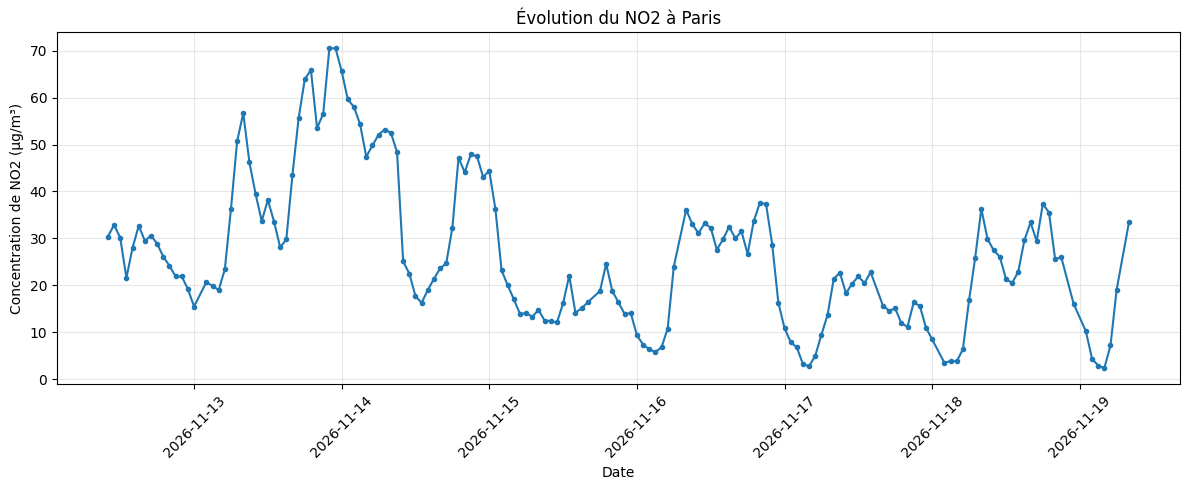

In [2]:

# Sélectionner les mesures de NO2 à Paris
paris_no2 = df[
    df["city"].fillna("").str.contains(
        "PARIS", case=False, regex=False
    )
    & (df["pollutant"] == "no2")
].copy()

paris_no2 = paris_no2.sort_values("timestamp")

plt.figure(figsize=(12, 5))

plt.plot(
    paris_no2["timestamp"],
    paris_no2["value"],
    marker=".",
    linewidth=1.5
)

plt.title("Évolution du NO2 à Paris")
plt.xlabel("Date")
plt.ylabel("Concentration de NO2 (µg/m³)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


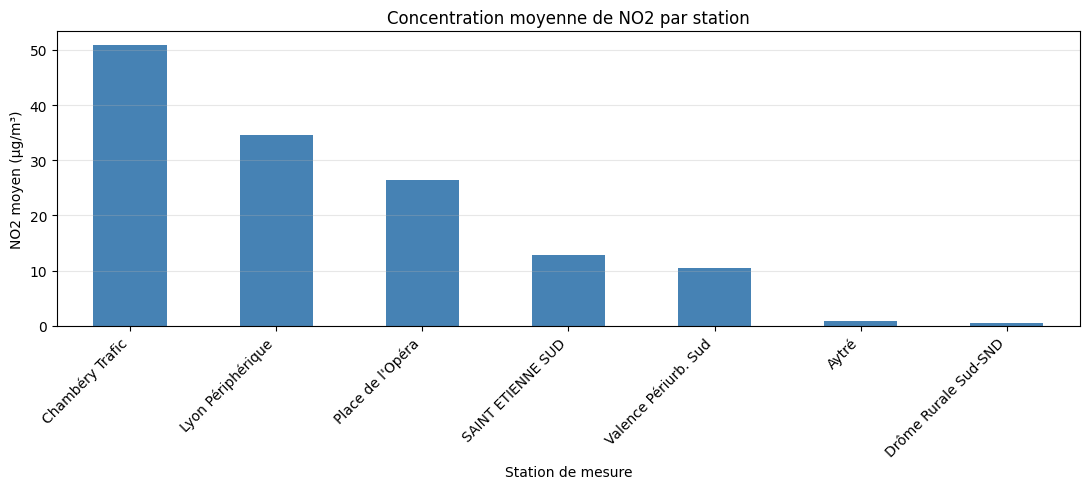

In [3]:

# Garder uniquement les mesures de NO2
no2 = df[df["pollutant"] == "no2"].copy()

# Calculer la concentration moyenne par station
moyennes = (
    no2.groupby("station_name")["value"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(11, 5))

moyennes.plot(kind="bar", color="steelblue")

plt.title("Concentration moyenne de NO2 par station")
plt.xlabel("Station de mesure")
plt.ylabel("NO2 moyen (µg/m³)")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


### Analyse des concentrations de NO2

Ce graphique compare les concentrations moyennes de dioxyde d'azote (NO2) enregistrées par les différentes stations disponibles dans notre jeu de données.

Il permet d'identifier les stations présentant les valeurs moyennes les plus élevées.

Les résultats doivent toutefois être interprétés avec prudence, car les stations ne disposent pas toutes du même nombre de mesures ni de la même période d'observation.

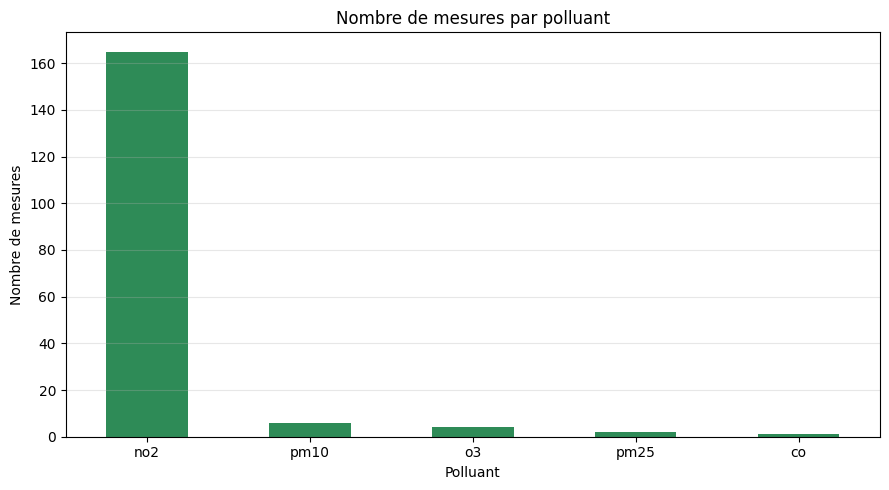

In [4]:

# Compter le nombre de mesures par polluant
polluants = df["pollutant"].value_counts()

plt.figure(figsize=(9, 5))

polluants.plot(kind="bar", color="seagreen")

plt.title("Nombre de mesures par polluant")
plt.xlabel("Polluant")
plt.ylabel("Nombre de mesures")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


### Répartition des mesures par polluant

Ce graphique présente le nombre de mesures disponibles pour chaque polluant dans notre jeu de données OpenAQ.

Il permet d'identifier les polluants les mieux représentés et de vérifier si nous disposons de suffisamment de données pour réaliser des analyses complémentaires.

Une différence dans le nombre de mesures ne signifie pas qu'un polluant est plus présent dans l'air qu'un autre.

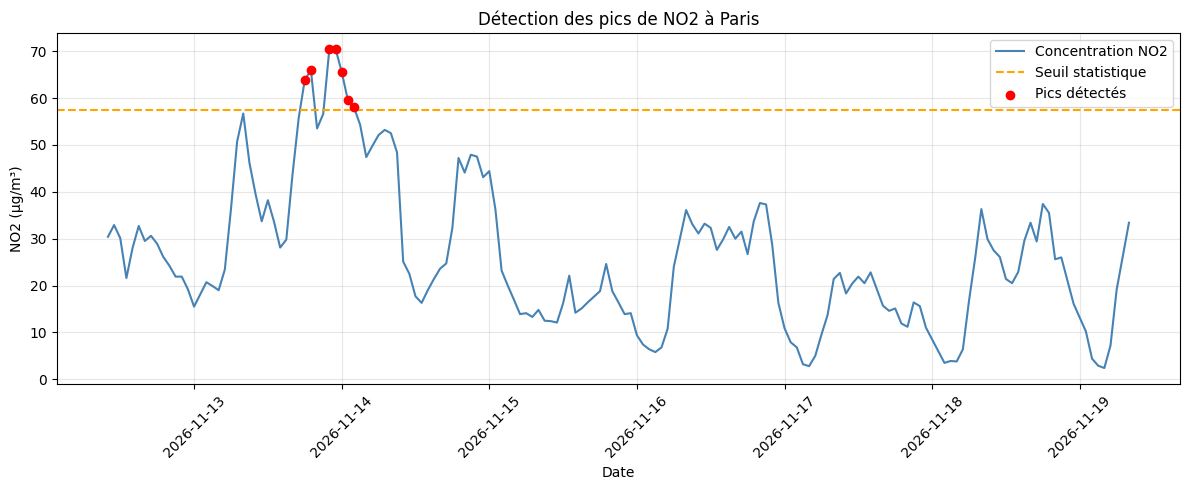

Seuil statistique : 57.50 µg/m³
Nombre de pics détectés : 7


In [5]:

# Détection des pics de NO2 à Paris

paris_no2 = paris_no2.dropna(
    subset=["timestamp", "value"]
).copy()

# Seuil statistique : moyenne + 2 écarts-types
moyenne = paris_no2["value"].mean()
ecart_type = paris_no2["value"].std()

seuil = moyenne + 2 * ecart_type

# Identifier les mesures dépassant le seuil
anomalies = paris_no2[paris_no2["value"] > seuil]

plt.figure(figsize=(12, 5))

plt.plot(
    paris_no2["timestamp"],
    paris_no2["value"],
    label="Concentration NO2",
    color="steelblue"
)

plt.axhline(
    seuil,
    color="orange",
    linestyle="--",
    label="Seuil statistique"
)

plt.scatter(
    anomalies["timestamp"],
    anomalies["value"],
    color="red",
    label="Pics détectés",
    zorder=5
)

plt.title("Détection des pics de NO2 à Paris")
plt.xlabel("Date")
plt.ylabel("NO2 (µg/m³)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Seuil statistique : {seuil:.2f} µg/m³")
print(f"Nombre de pics détectés : {len(anomalies)}")


### Détection des anomalies de pollution

Nous avons utilisé une méthode statistique simple pour identifier les pics de concentration de NO2 à Paris.

Le seuil de détection est calculé à partir de la moyenne des mesures, à laquelle nous ajoutons deux écarts-types.

Les valeurs dépassant ce seuil sont considérées comme des anomalies statistiques potentielles.

Cette analyse permet de repérer des épisodes inhabituels de pollution qui pourraient faire l'objet d'une étude plus approfondie.